# 03 · Threshold tuning, SHAP explanations and saving the model

1. Choose the decision threshold with a **business cost model** instead of the default 0.5
2. Explain the model with **SHAP**, globally and for individual transactions
3. Save the final model and threshold for the app

In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from fraudguard.config import FIGURES_DIR, MODELS_DIR, RANDOM_STATE, TARGET
from fraudguard.cost import REVIEW_COST, best_threshold, evaluate_threshold, threshold_table
from fraudguard.data import load_data
from fraudguard.explain import explain
from fraudguard.models import build_pipeline, xgboost
from fraudguard.plotting import (FRAUD_COLOR, MUTED_COLOR, NORMAL_COLOR, apply_style,
                                 plot_confusion_matrix)
from fraudguard.predict import MODEL_PATH, load_model, predict, save_model
from fraudguard.preprocessing import split_data

apply_style()
pd.set_option("display.precision", 3)

df = load_data()
X_train, X_test, y_train, y_test = split_data(df)  # same split as notebook 02 (fixed seed)

## 1 · Why not just use 0.5?

The model outputs a fraud **probability**. We flag a transaction when probability ≥ threshold. 0.5 is only a
convention: it implicitly assumes a missed fraud and a false alarm cost the same, which is not true for a bank.

**Cost model** (simple, but captures the asymmetry):

| Mistake | Cost |
|---|---|
| **Missed fraud** (false negative) | the transaction **Amount** (the bank refunds the customer) |
| **False alarm** (false positive) | a fixed **review cost of 5** (analyst time + annoyed customer) |

The review cost is a **business assumption**; a real bank would estimate it from its own operations. Notice that
most frauds are small (median 9.25), so for those a false alarm can cost about as much as the fraud itself.

### Don't tune the threshold on the test set

Choosing the threshold is a form of training: if we picked it by looking at the test set, the test result would
be optimistic. So we generate **out-of-fold predictions** on the training set: 5-fold cross-validation where every
training transaction is scored by a model that did *not* see it. We choose the threshold on those, then check it
once on the test set.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_scores = cross_val_predict(build_pipeline(xgboost()), X_train, y_train, cv=cv,
                               method="predict_proba")[:, 1]

oof_table = threshold_table(y_train, oof_scores, X_train["Amount"], review_cost=REVIEW_COST)
chosen_threshold = best_threshold(y_train, oof_scores, X_train["Amount"], review_cost=REVIEW_COST)
print(f"Cost-optimal threshold (on out-of-fold training predictions): {chosen_threshold}")

oof_table.set_index("threshold").loc[[0.003, 0.005, chosen_threshold, 0.02, 0.05, 0.1, 0.2, 0.5, 0.9]]

Cost-optimal threshold (on out-of-fold training predictions): 0.01


,precision,recall,frauds_caught,frauds_missed,false_alarms,missed_fraud_cost,false_alarm_cost,total_cost
threshold,,,,,,,,
0.003,0.359,0.876,345,49,615,9935.43,3075.0,13010.43
0.005,0.454,0.871,343,51,412,11036.03,2060.0,13096.03
0.010,0.583,0.865,341,53,244,11041.39,1220.0,12261.39
0.020,0.710,0.853,336,58,137,11602.17,685.0,12287.17
0.050,0.834,0.830,327,67,65,12918.63,325.0,13243.63
0.100,0.876,0.825,325,69,46,12923.39,230.0,13153.39
0.200,0.907,0.817,322,72,33,12929.06,165.0,13094.06
0.500,0.939,0.787,310,84,20,14308.13,100.0,14408.13
0.900,0.972,0.706,278,116,8,18544.64,40.0,18584.64


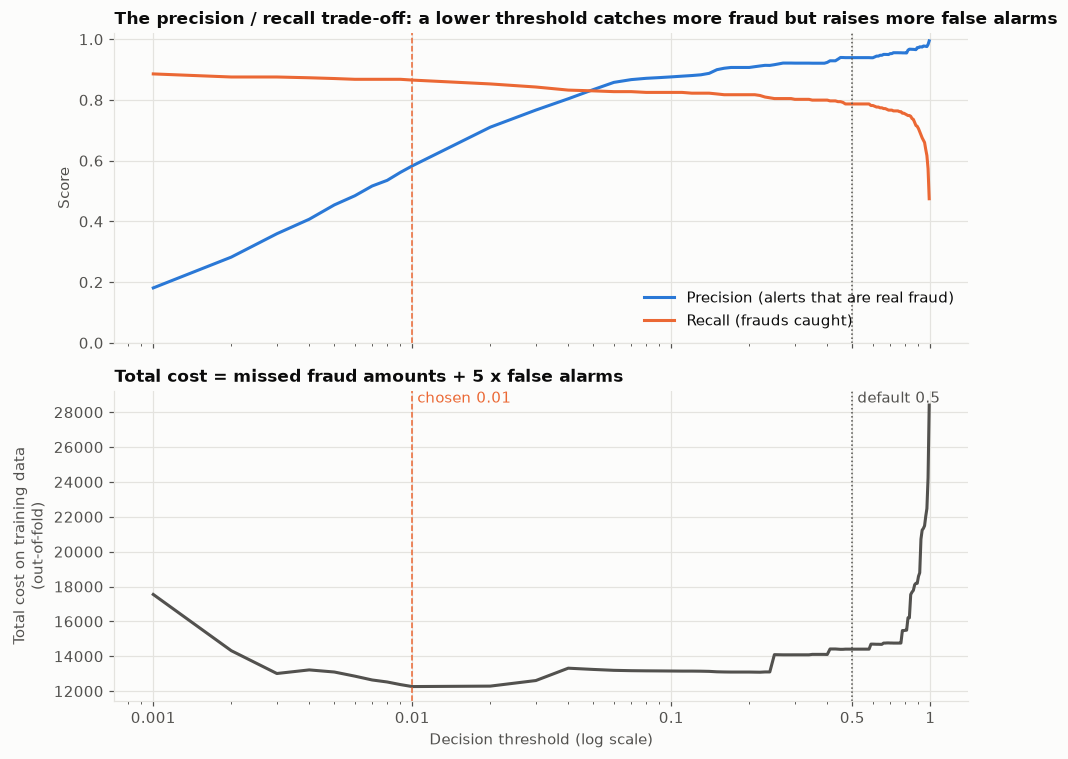

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
t = oof_table["threshold"]

ax1.plot(t, oof_table["precision"], color=NORMAL_COLOR, label="Precision (alerts that are real fraud)")
ax1.plot(t, oof_table["recall"], color=FRAUD_COLOR, label="Recall (frauds caught)")
ax1.set_ylabel("Score")
ax1.set_ylim(0, 1.02)
ax1.set_title("The precision / recall trade-off: a lower threshold catches more fraud but raises more false alarms")
ax1.legend(loc="lower right")

ax2.plot(t, oof_table["total_cost"], color=MUTED_COLOR, label="Total cost")
ax2.set_ylabel("Total cost on training data\n(out-of-fold)")
ax2.set_xlabel("Decision threshold (log scale)")
ax2.set_title("Total cost = missed fraud amounts + 5 x false alarms")

for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.axvline(0.5, color=MUTED_COLOR, linestyle=":", linewidth=1)
    ax.axvline(chosen_threshold, color=FRAUD_COLOR, linestyle="--", linewidth=1)
ax2.text(0.5, ax2.get_ylim()[1], " default 0.5", va="top", color=MUTED_COLOR)
ax2.text(chosen_threshold, ax2.get_ylim()[1], f" chosen {chosen_threshold}", va="top", color=FRAUD_COLOR)
ax2.set_xticks([0.001, 0.01, 0.1, 0.5, 1], ["0.001", "0.01", "0.1", "0.5", "1"])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "threshold_tradeoff.png")
plt.show()

**Reading the chart:**
- Very low thresholds (≤ 0.003) flag hundreds of genuine transactions: false-alarm costs explode.
- High thresholds (≥ 0.3) miss more frauds: missed-fraud costs rise.
- The minimum is at a **low threshold**: since a missed fraud costs ~122 on average and a false alarm only 5,
  it pays to be suspicious.
- The curve is quite **flat** between ~0.01 and ~0.2. The threshold isn't a precise number; it's a region of
  reasonable choices.

### Checking on the test set (once)

In [4]:
final_model = build_pipeline(xgboost()).fit(X_train, y_train)
test_scores = final_model.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "Default 0.5": evaluate_threshold(y_test, test_scores, X_test["Amount"], 0.5),
    f"Chosen {chosen_threshold}": evaluate_threshold(y_test, test_scores, X_test["Amount"], chosen_threshold),
}).T.drop(columns="threshold")
no_model_cost = X_test.loc[y_test == 1, "Amount"].sum()
comparison.loc["No model (miss every fraud)"] = [0, 0, 0, int(y_test.sum()), 0, no_model_cost, 0, no_model_cost]
comparison

,precision,recall,frauds_caught,frauds_missed,false_alarms,missed_fraud_cost,false_alarm_cost,total_cost
Default 0.5,0.930,0.816,80.0,18.0,6.0,1969.00,30.0,1999.00
Chosen 0.01,0.541,0.867,85.0,13.0,72.0,1830.72,360.0,2190.72
No model (miss every fraud),0.000,0.000,0.0,98.0,0.0,10644.93,0.0,10644.93


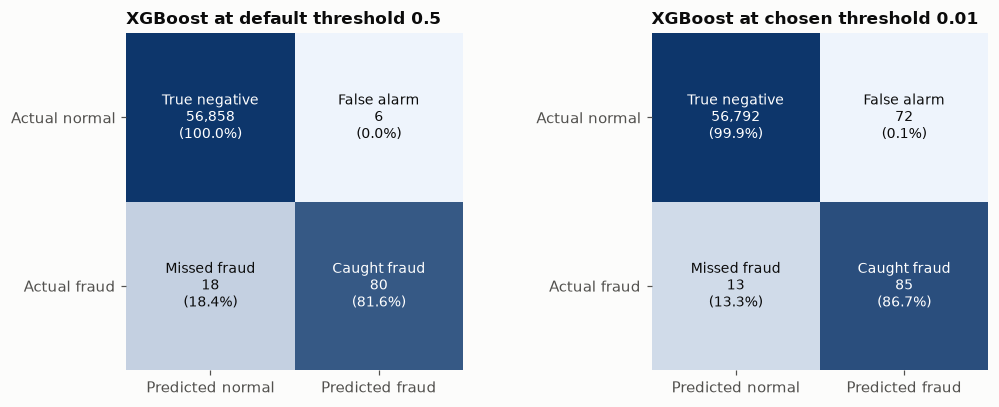

Amounts of the frauds still missed: [1.0, 1.0, 1.0, 1.79, 2.47, 3.22, 3.79, 4.49, 29.95, 98.01, 519.9, 529.0, 635.1]


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
plot_confusion_matrix(axes[0], y_test, (test_scores >= 0.5).astype(int), "XGBoost at default threshold 0.5")
plot_confusion_matrix(axes[1], y_test, (test_scores >= chosen_threshold).astype(int),
                      f"XGBoost at chosen threshold {chosen_threshold}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrix_final.png")
plt.show()

missed = (y_test == 1) & (test_scores < chosen_threshold)
print("Amounts of the frauds still missed:", sorted(X_test.loc[missed, "Amount"].round(2)))

**What happened on the test set (honest reading):**
- The chosen threshold catches **85 of 98 frauds (86.7%)** instead of 80, but raises **72 false alarms** instead of 6.
  Precision drops to 0.54: about one in two alerts is a real fraud, which is a common operating point for fraud teams.
- **Both thresholds cut losses by ~80%** compared with having no model (cost ~2,000 vs 10,645).
- On *this* test set the chosen threshold is slightly **more expensive** (2,191 vs 1,999). The 5 extra frauds it caught
  were small (138 in total), while the 66 extra false alarms cost 330.
- Most of the remaining cost comes from **three frauds of 520–635** that the model scores below even 0.01. No reasonable
  threshold catches them.

Is the threshold wrong, then? Not necessarily: with only 98 test frauds, a single large fraud swings the total. Look at how
much the "best" threshold moves if we pick it on each cross-validation fold separately:

In [6]:
fold_thresholds = [
    best_threshold(y_train.iloc[val], oof_scores[val], X_train["Amount"].iloc[val])
    for _, val in cv.split(X_train, y_train)
]
print("Best threshold on each fold:", fold_thresholds)

Best threshold on each fold: [0.003, 0.004, 0.17, 0.44, 0.01]


The best threshold jumps around between folds: the cost curve is flat and the estimate is noisy. We keep the threshold
chosen on the full training data (re-choosing it from the test set would be cheating, and would just fit the noise in
98 frauds). In production you would **monitor** cost per week and re-tune the threshold as more fraud data arrives.

The threshold also depends on the business assumption about review cost:

In [7]:
# The best threshold depends on the business assumption: how expensive is a false alarm?
sensitivity = pd.DataFrame([
    {"review cost per false alarm": cost,
     "best threshold": best_threshold(y_train, oof_scores, X_train["Amount"], review_cost=cost)}
    for cost in [1, 5, 25, 100]
])
sensitivity

,review cost per false alarm,best threshold
0,1,0.003
1,5,0.010
2,25,0.230
3,100,0.230


The more a false alarm costs, the higher (stricter) the threshold. That's why the threshold is a **business
decision**, and why the app has a live threshold explorer with an adjustable review cost.

## 2 · Explaining the model with SHAP

**SHAP** (SHapley Additive exPlanations) answers: *how much did each feature push this prediction up or down?*
It comes from game theory: features are "players" sharing the credit for the prediction fairly. For each
transaction:

> model output = average output (base value) + contribution of `V14` + contribution of `Amount` + ...

For XGBoost the output is in **log-odds** (positive = towards fraud). `TreeExplainer` computes exact SHAP values
quickly for tree models.

### Global view: which features matter most?

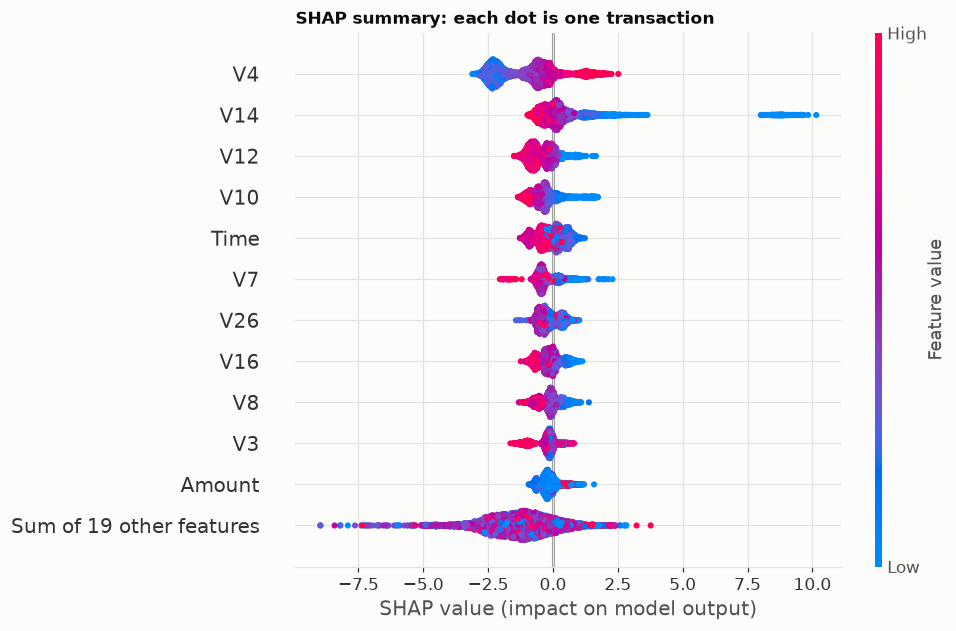

In [8]:
# A random sample of 5,000 test transactions plus all test frauds, so the fraud patterns are visible.
sample_idx = X_test.sample(5000, random_state=RANDOM_STATE).index.union(X_test.index[y_test == 1])
shap_values = explain(final_model, X_test.loc[sample_idx])

shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP summary: each dot is one transaction", loc="left", fontweight="bold")
plt.gcf().savefig(FIGURES_DIR / "shap_summary.png")
plt.show()

**How to read it:** features are sorted by overall importance. Each dot is a transaction; its position shows how much
that feature pushed the prediction towards fraud (right) or normal (left). Colour shows the feature's value (red = high,
blue = low).

**Observations:**
- **`V4`** and **`V14`** are the two most important features. High `V4` (red) pushes towards fraud; **low `V14`** (blue)
  pushes towards fraud, and has the most extreme effects of any feature (the cluster at +8 to +10).
- `V12` and `V10` follow: low values push towards fraud. This matches the EDA, where V14, V17, V12 and V10 had the
  strongest correlation with fraud.
- **`Time`** is the 5th most important feature, which fits the night-time pattern found in the EDA.
- `Amount` matters, but much less than the top V features.

**Honest limitation:** `V1`–`V28` are anonymised PCA components. SHAP tells us *"V14 was very low, which is typical of
fraud"*, but not what V14 means (merchant type? location? device?). With the original features, a fraud analyst
could get explanations like *"new device + foreign merchant + unusual hour"*. Here the explanations are useful
for debugging and trust in the model, but not for telling a customer **why** their card was blocked.

### Individual predictions

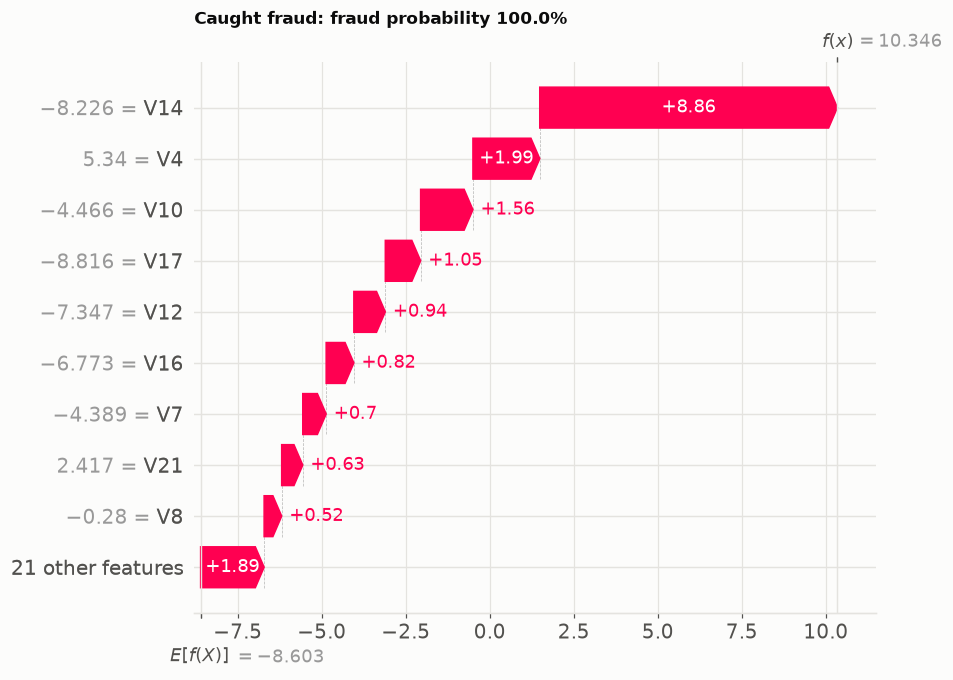

In [9]:
def explain_one(index, title):
    probability = test_scores[X_test.index.get_loc(index)]
    one = explain(final_model, X_test.loc[[index]])[0]  # SHAP values for this single transaction
    shap.plots.waterfall(one, max_display=10, show=False)
    plt.title(f"{title}: fraud probability {probability:.1%}", loc="left", fontweight="bold")
    return plt.gcf()

scores_s = pd.Series(test_scores, index=X_test.index)
frauds = scores_s[y_test == 1]
normals = scores_s[y_test == 0]

caught_fraud = frauds.idxmax()                        # the fraud the model is most sure about
missed_fraud = frauds[frauds < chosen_threshold].idxmax()  # a fraud we missed
false_alarm = normals.idxmax()                        # the most suspicious genuine transaction

fig = explain_one(caught_fraud, "Caught fraud")
fig.savefig(FIGURES_DIR / "shap_waterfall_fraud.png")
plt.show()

**Reading a waterfall:** start at the bottom with E[f(X)], the model's average output (very negative, since fraud is
rare). Each bar adds one feature's contribution (red pushes towards fraud, blue towards normal), ending at f(x), the
output for this transaction. The grey numbers are the transaction's actual feature values.

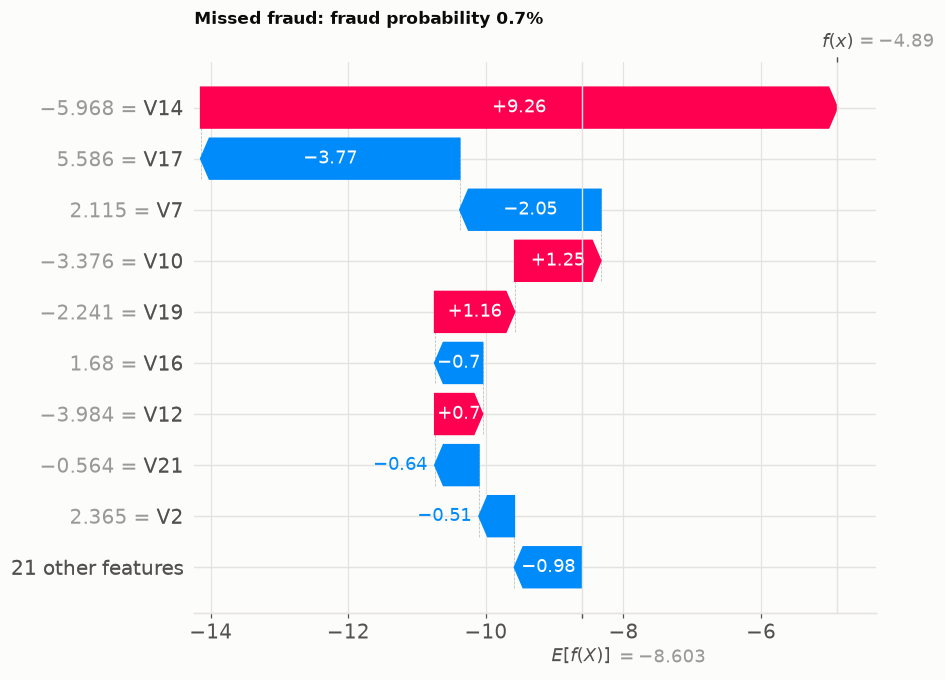

In [10]:
explain_one(missed_fraud, "Missed fraud")
plt.show()

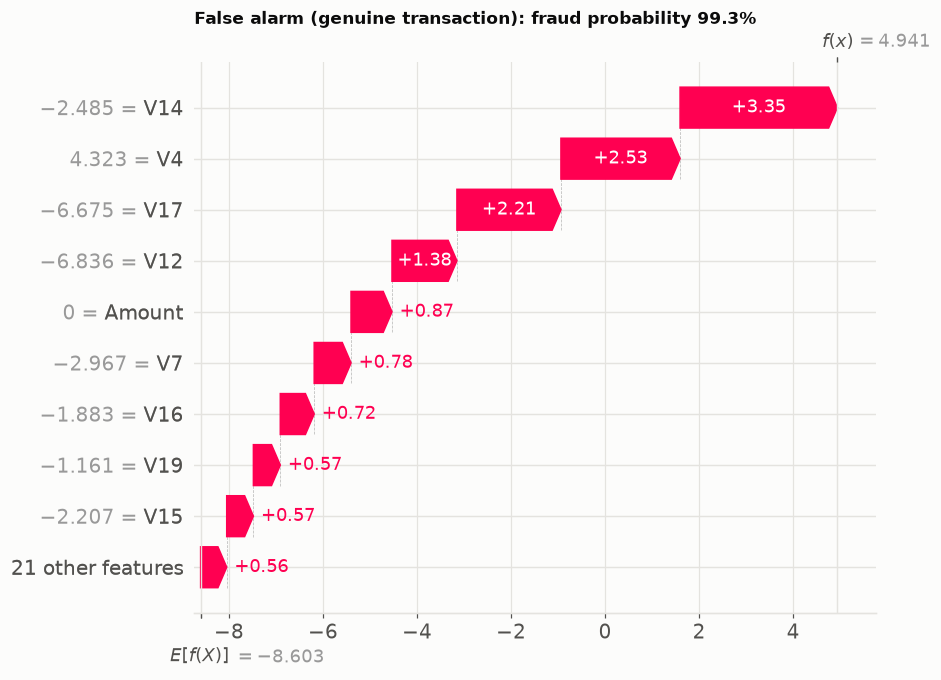

In [11]:
explain_one(false_alarm, "False alarm (genuine transaction)")
plt.show()

- The **missed fraud** sends mixed signals: low `V14` pushes strongly towards fraud (+9.3), but an unusually high `V17`
  and `V7` pull it back towards normal. It ends at 0.7%, **just below** our 1% threshold. A borderline case like this is
  exactly what the threshold choice is about.
- The **false alarm** is a genuine transaction of amount **0** with fraud-like values on `V14`, `V4`, `V17` and `V12`
  (a zero-amount check looks like the card-testing pattern from the EDA). An analyst would see the same "reasons" as for a
  real fraud, which shows why some false alarms are unavoidable.

## 3 · Save the final model

We save the **whole pipeline** (scaler + XGBoost), so the app can feed raw transactions straight in, together
with the threshold it must be used with.

In [12]:
save_model(final_model, threshold=chosen_threshold, review_cost=REVIEW_COST)
size_kb = MODEL_PATH.stat().st_size / 1024
print(f"Saved {MODEL_PATH.name} ({size_kb:.0f} KB)")

# Check that it loads and gives the same answers.
bundle = load_model()
reloaded = predict(bundle, X_test)
assert np.allclose(reloaded["fraud_probability"], test_scores)
print("Reloaded model OK, threshold =", bundle["threshold"])
reloaded.head()

Saved fraudguard_model.joblib (114 KB)
Reloaded model OK, threshold = 0.01


,fraud_probability,is_fraud
263020,2.670e-07,0
11378,3.970e-07,0
147283,7.592e-05,0
219439,1.062e-07,0
36939,3.149e-06,0


In [13]:
# A small set of test transactions for the app's "Transaction checker" page:
# every test fraud plus 2,000 random normal transactions (~0.5 MB).
normal_sample = X_test[y_test == 0].sample(2000, random_state=RANDOM_STATE).index
app_idx = X_test.index[y_test == 1].union(normal_sample)
sample_transactions = X_test.loc[app_idx].assign(**{TARGET: y_test.loc[app_idx]})
joblib.dump(sample_transactions, MODELS_DIR / "sample_transactions.joblib", compress=3)
print(f"Saved {len(sample_transactions):,} sample transactions for the app")

Saved 2,098 sample transactions for the app


## Summary

| | Result |
|---|---|
| Final model | XGBoost (scaler + model in one pipeline), 114 KB |
| PR-AUC / ROC-AUC on test | 0.867 / 0.980 |
| Chosen threshold | **0.01** (lowest total cost on out-of-fold training predictions, review cost = 5) |
| At that threshold (test) | precision 0.54, recall 0.87: 85 of 98 frauds caught, 72 false alarms |
| Cost (test) | 2,191 vs 10,645 with no model (−79%). The default 0.5 threshold scored 1,999 on this test set, within noise. |

Main lessons: choose metrics that focus on the rare class, pick the threshold with the business in mind, and be honest
about how noisy results are with only 98 test frauds.